# 06 · FastSAM-s over time: sequences around the picks

Notebook 05 found FastSAM-s (`imgsz 1024`, `conf 0.4`) the most promising cheap
alternative to SAM 3: recall 0.42 / precision 0.43 against SAM 3 at about 1 s
per frame, roughly 50x faster. That was 18 single frames. Here we look at
**video**: a 5-second window around each of the 18 picks (windows that
overlap are merged into one sequence), with FastSAM-s run on a **stride** of
frames and the gaps filled two ways, so the two can be compared side by side:

* **hold** - repeat the last detection until the next one (free).
* **flow** - warp the last detection forward with dense optical flow each
  frame (`classical.dense_flow` / `classical.warp_mask`, cheap: tens of ms).

**Why not run FastSAM on every frame.** 1611 frames across the 9 sequences at
about 1 s/frame is 27 minutes, and that is *before* trying more than one
setting. Segmenting only every 5th frame (6 "detections" a second) cuts that
to about 5 minutes, 328 calls.

**Segment then track, but two different things are called "tracking".**
Giving the same object a consistent id across frames you *already* segmented
is cheap (mask IoU matching - `segmentation.link_tracks`, built on
`match_instances`) and does not save any compute. What saves compute is not
re-running FastSAM on every frame, and that is a *different* job: predicting
where an already-found object went, using motion (optical flow), not a new
detection. Both are used here: `link_tracks` gives a persistent id to each
flower head across the sparse detections, and the flow/hold step decides what
to draw for the frames in between.

**The `flowerlike` filter's "not grey" check is switched off** (`min_sat=0`)
for this notebook: it was the one part of the filter that has a real, known
cost (it throws away white and pale flowers), and section 17 of notebook 05
did not need it to reject FastSAM's failure modes (huge merged blobs, wrapping
paper) - size, colour-vs-green and solidity did that on their own.

Contents: 1 The sequences · 2 Detect on keyframes · 3 Link ids across
keyframes · 4 Render: hold vs optical flow · 5 Watch a sequence · 6 Filmstrips
· 7 Did optical flow help? · 8 Take-aways

## 1 · The sequences

Same picks and video as notebooks 04/05. A 5-second window (+/- 2.5 s) around
each pick; windows that overlap become one sequence.

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bouquet_checker import classical as cl
from bouquet_checker import segmentation as sg
from bouquet_checker import video
from bouquet_checker.config import DATASET_DIR
from bouquet_checker.framepicker import FramePicker

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

VIDEO_URL = "https://www.youtube.com/watch?v=QSVyyrKea14"
WINDOW_S = 2.5           # +/- around each pick
STRIDE = 5               # run FastSAM-s every 5th frame (6 detections/second)
SCALE = 3                # masks and rendered frames at 1/3 resolution (427 x 240)
FASTSAM_KWARGS = {"imgsz": 1024, "conf": 0.4}     # the best setting from notebook 05

path = video.download_video(VIDEO_URL, max_height=720)
info = video.video_info(path)
with FramePicker(path) as picker:
    picker.load()
    picks = list(picker.picks)
print(f"{len(picks)} picks, {info.fps:.0f} fps, {info.frame_count} frames")

18 picks, 30 fps, 11968 frames


In [2]:
def merge_windows(picks, window_s, fps, last_index):
    half = round(window_s * fps)
    spans = sorted((max(p - half, 0), min(p + half, last_index)) for p in picks)
    merged = []
    for lo, hi in spans:
        if merged and lo <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], hi))
        else:
            merged.append((lo, hi))
    return merged


sequences = merge_windows(picks, WINDOW_S, info.fps, info.frame_count - 1)
total_frames = sum(hi - lo + 1 for lo, hi in sequences)
table = pd.DataFrame([{"sequence": n, "first frame": lo, "last frame": hi,
                       "seconds": (hi - lo) / info.fps, "frames": hi - lo + 1,
                       "picks inside": sum(lo <= p <= hi for p in picks)}
                      for n, (lo, hi) in enumerate(sequences)])
print(f"{len(sequences)} sequences, {total_frames} frames in total "
      f"(vs {len(picks)} single frames in notebook 05)")
table

9 sequences, 1611 frames in total (vs 18 single frames in notebook 05)


,sequence,first frame,last frame,seconds,frames,picks inside
0,0,1545,1695,5.000000,151,1
1,1,2965,3148,6.100000,184,3
2,2,3198,3375,5.900000,178,2
3,3,3435,3690,8.500000,256,5
4,4,3870,4102,7.733333,233,2
5,5,4208,4363,5.166667,156,2
6,6,4798,4948,5.000000,151,1
7,7,4973,5123,5.000000,151,1
8,8,5370,5520,5.000000,151,1


## 2 · Detect on keyframes

FastSAM-s only runs on every `STRIDE`-th frame of each sequence (plus the
last frame, so a sequence is never left without a detection near its end).
Raw masks are cached per frame; the `flowerlike` filter (green/size/solidity,
**no grey check**) is applied fresh each time, so changing it needs no
re-detection.

In [3]:
CACHE_DIR = DATASET_DIR / "cache" / "fastsam_track"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
_model = None


def fastsam():
    global _model
    if _model is None:
        _model = sg.FastSamSegmenter()
    return _model


def raw_fastsam(index, frame_image):
    cache_file = CACHE_DIR / f"{path.stem}_f{index}.npz"
    if cache_file.exists():
        return sg.load_results(cache_file)["raw"]
    masks = fastsam().segment(frame_image, downscale=SCALE, **FASTSAM_KWARGS)
    sg.save_results(cache_file, {"raw": masks})
    return masks


def keyframes_for(lo, hi, stride):
    frames = list(range(lo, hi + 1, stride))
    if frames[-1] != hi:
        frames.append(hi)
    return frames


def small(image):
    return image.resize((-(-image.width // SCALE), -(-image.height // SCALE)))


keyframes = {n: keyframes_for(lo, hi, STRIDE) for n, (lo, hi) in enumerate(sequences)}
n_keyframes = sum(len(k) for k in keyframes.values())
print(f"{n_keyframes} keyframes across {len(sequences)} sequences "
      f"(1 every {STRIDE} frames = {info.fps / STRIDE:.1f} detections/second)")

started = time.perf_counter()
kept_by_index = {}
with video.FrameReader(path) as reader:
    for n, idxs in keyframes.items():
        for index in idxs:
            if index not in kept_by_index:
                frame_image = reader.read(index).image
                raw = raw_fastsam(index, frame_image)
                kept_by_index[index] = cl.flowerlike(raw, small(frame_image), min_sat=0)
        print(f"  sequence {n}: {len(idxs)} keyframes done "
              f"({time.perf_counter() - started:.0f} s so far)", flush=True)
del _model
gc.collect()
print(f"done in {time.perf_counter() - started:.0f} s")

331 keyframes across 9 sequences (1 every 5 frames = 6.0 detections/second)


  sequence 0: 31 keyframes done (8 s so far)


  sequence 1: 38 keyframes done (17 s so far)


  sequence 2: 37 keyframes done (24 s so far)


  sequence 3: 52 keyframes done (35 s so far)


...

  sequence 5: 32 keyframes done (49 s so far)


  sequence 6: 31 keyframes done (54 s so far)


  sequence 7: 31 keyframes done (61 s so far)


  sequence 8: 31 keyframes done (67 s so far)


done in 67 s


## 3 · Link ids across keyframes

`segmentation.link_tracks` matches each keyframe's kept instances to the
previous keyframe's by mask IoU (>= 0.5), carrying an id forward on a match
and starting a new one otherwise. Keyframes are `STRIDE` frames (about
0.17 s) apart, so a flower usually barely moves between them.

In [4]:
tracks_by_seq = {}
for n, idxs in keyframes.items():
    frame_lists = [kept_by_index[i] for i in idxs]
    tracks, next_id = sg.link_tracks(frame_lists, iou_threshold=0.5)
    tracks_by_seq[n] = tracks

lifetimes = pd.Series([
    sum(tid in frame for frame in tracks_by_seq[n])
    for n in tracks_by_seq for tid in {t for frame in tracks_by_seq[n] for t in frame}
])
print(f"{len(lifetimes)} tracks in total, present for {lifetimes.mean():.1f} keyframes on "
      f"average (of up to {max(len(k) for k in keyframes.values())}); "
      f"{(lifetimes == 1).mean():.0%} appear in only one keyframe (no real track)")
lifetimes.value_counts().sort_index()

14096 tracks in total, present for 1.3 keyframes on average (of up to 52); 88% appear in only one keyframe (no real track)


1     12367
2       860
3       393
4       191
5        87
6        72
7        32
8        25
9        17
10       15
11       13
12        6
13        3
14        1
15        3
16        2
17        1
18        4
19        1
20        1
23        2
Name: count, dtype: int64

## 4 · Render: hold vs optical flow

For every frame of every sequence (not just the keyframes): at a keyframe,
both variants snap to the real detection; in between, **hold** repeats the
last snap and **flow** warps it forward with `classical.dense_flow` /
`classical.warp_mask` computed between consecutive *small* (427 x 240)
frames. `segmentation.overlay_tracks` colours each id consistently. The
drift check in section 7 is recorded here too: right before a snap, we
compare the *about-to-be-overwritten* guess of each variant with the real
detection that replaces it.

In [5]:
RENDER_DIR = DATASET_DIR / "cache" / "fastsam_track"


def render_sequence(n):
    lo, hi = sequences[n]
    idxs = keyframes[n]
    tracks = tracks_by_seq[n]
    hold_frames, flow_frames, drift_rows = [], [], []
    active_hold, active_flow = {}, {}
    prev_gray = None
    kf_pointer = 0
    with video.FrameReader(path) as reader:
        for index in range(lo, hi + 1):
            frame_image = small(reader.read(index).image)
            gray = cl.grayscale(frame_image)
            if kf_pointer < len(idxs) and index == idxs[kf_pointer]:
                real = {tid: inst.mask for tid, inst in tracks[kf_pointer].items()}
                if kf_pointer > 0:
                    for tid, mask in real.items():
                        if tid in active_hold:
                            drift_rows.append({
                                "sequence": n, "track": tid, "to_keyframe": kf_pointer,
                                "iou_hold": sg.mask_iou(active_hold[tid], mask),
                                "iou_flow": sg.mask_iou(active_flow.get(tid, active_hold[tid]), mask),
                            })
                active_hold, active_flow = dict(real), dict(real)
                kf_pointer += 1
            elif prev_gray is not None:
                flow = cl.dense_flow(prev_gray, gray)
                active_flow = {tid: cl.warp_mask(mask, flow) for tid, mask in active_flow.items()}
            hold_frames.append(sg.overlay_tracks(frame_image, active_hold))
            flow_frames.append(sg.overlay_tracks(frame_image, active_flow))
            prev_gray = gray
    return hold_frames, flow_frames, drift_rows


started = time.perf_counter()
all_drift_rows = []
video_paths = {}
for n in range(len(sequences)):
    hold_video = RENDER_DIR / f"{path.stem}_seq{n}_hold.mp4"
    flow_video = RENDER_DIR / f"{path.stem}_seq{n}_flow.mp4"
    if hold_video.exists() and flow_video.exists():
        video_paths[n] = (hold_video, flow_video)
        continue
    hold_frames, flow_frames, drift_rows = render_sequence(n)
    video.write_video(hold_frames, hold_video, fps=info.fps)
    video.write_video(flow_frames, flow_video, fps=info.fps)
    all_drift_rows.extend(drift_rows)
    video_paths[n] = (hold_video, flow_video)
    print(f"  sequence {n}: {len(hold_frames)} frames rendered "
          f"({time.perf_counter() - started:.0f} s so far)", flush=True)
print(f"done in {time.perf_counter() - started:.0f} s")

  sequence 0: 151 frames rendered (46 s so far)


  sequence 1: 184 frames rendered (86 s so far)


  sequence 2: 178 frames rendered (131 s so far)


  sequence 3: 256 frames rendered (203 s so far)


  sequence 4: 233 frames rendered (238 s so far)


  sequence 5: 156 frames rendered (274 s so far)


  sequence 6: 151 frames rendered (311 s so far)


  sequence 7: 151 frames rendered (353 s so far)


  sequence 8: 151 frames rendered (378 s so far)


done in 378 s


## 5 · Watch a sequence

Run this cell live (a saved notebook only shows the file paths, not a player)
to watch the hold and flow renders side by side for one sequence.

In [6]:
from IPython.display import HTML, display

SHOW_SEQ = 3

hold_path, flow_path = video_paths[SHOW_SEQ]
display(HTML(f'''
<div style="display:flex; gap:12px;">
  <div><b>hold</b><video src="{hold_path.as_posix()}" controls width="380"></video></div>
  <div><b>flow</b><video src="{flow_path.as_posix()}" controls width="380"></video></div>
</div>
'''))
print(hold_path)
print(flow_path)

C:\Users\carl0\vsc\cat-project\data\raw\cache\fastsam_track\QSVyyrKea14_seq3_hold.mp4
C:\Users\carl0\vsc\cat-project\data\raw\cache\fastsam_track\QSVyyrKea14_seq3_flow.mp4


## 6 · Filmstrips

Eight evenly spaced frames of a sequence, hold on top and flow underneath, so
the archived notebook shows something without needing to play the videos.
Sequence 3 (frames {lo}-{hi}) has the most keyframes; sequence 0 is a single,
mostly static bouquet close-up for contrast.

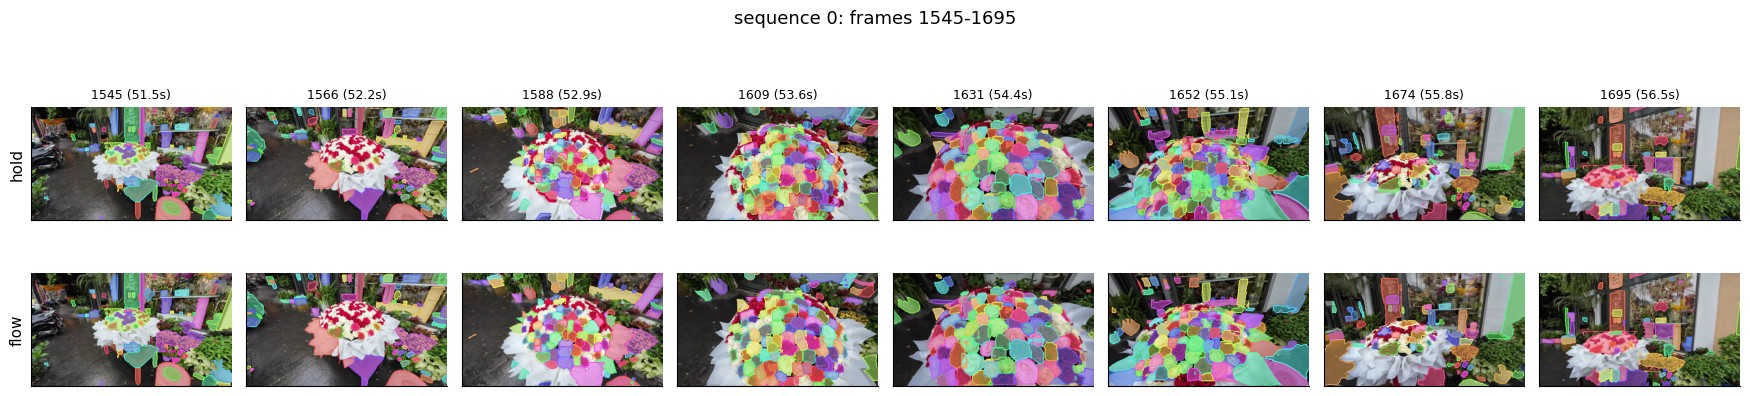

In [7]:
def show_filmstrip(n, count=8):
    lo, hi = sequences[n]
    positions = np.linspace(0, hi - lo, count).round().astype(int)
    hold_frames, flow_frames, _ = render_sequence(n)
    fig, axes = plt.subplots(2, count, figsize=(2.2 * count, 4.6))
    for c, p in enumerate(positions):
        axes[0, c].imshow(hold_frames[p])
        axes[0, c].set_title(f"{lo + p} ({(lo + p) / info.fps:.1f}s)", fontsize=9)
        axes[1, c].imshow(flow_frames[p])
    axes[0, 0].set_ylabel("hold", fontsize=11)
    axes[1, 0].set_ylabel("flow", fontsize=11)
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"sequence {n}: frames {lo}-{hi}", fontsize=13)
    plt.tight_layout()
    plt.show()


show_filmstrip(0)

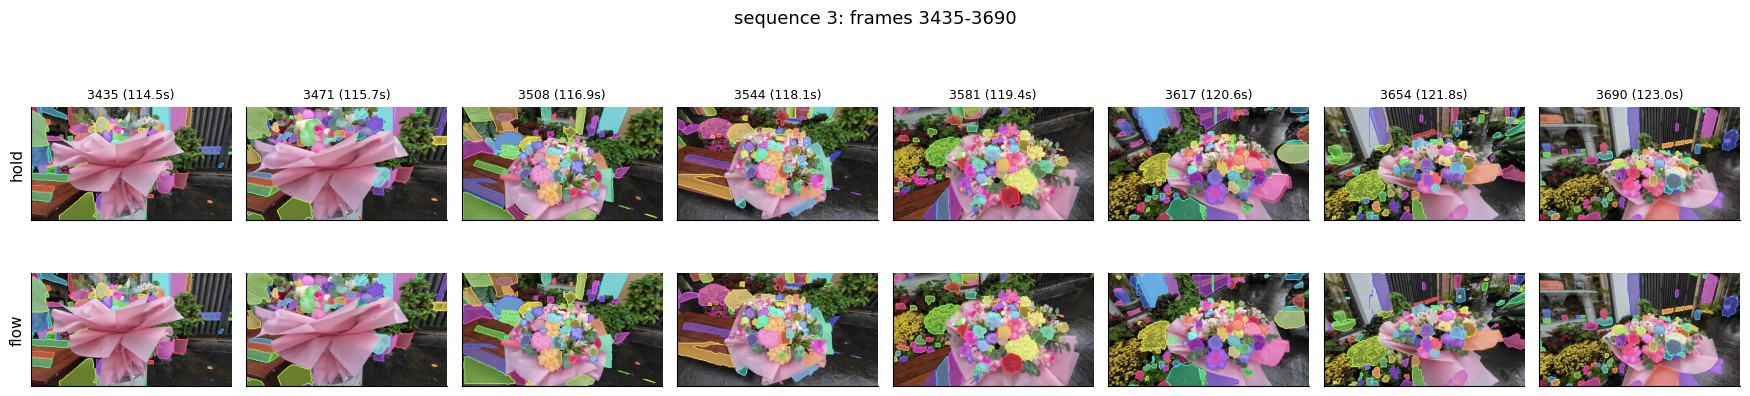

In [8]:
show_filmstrip(3)

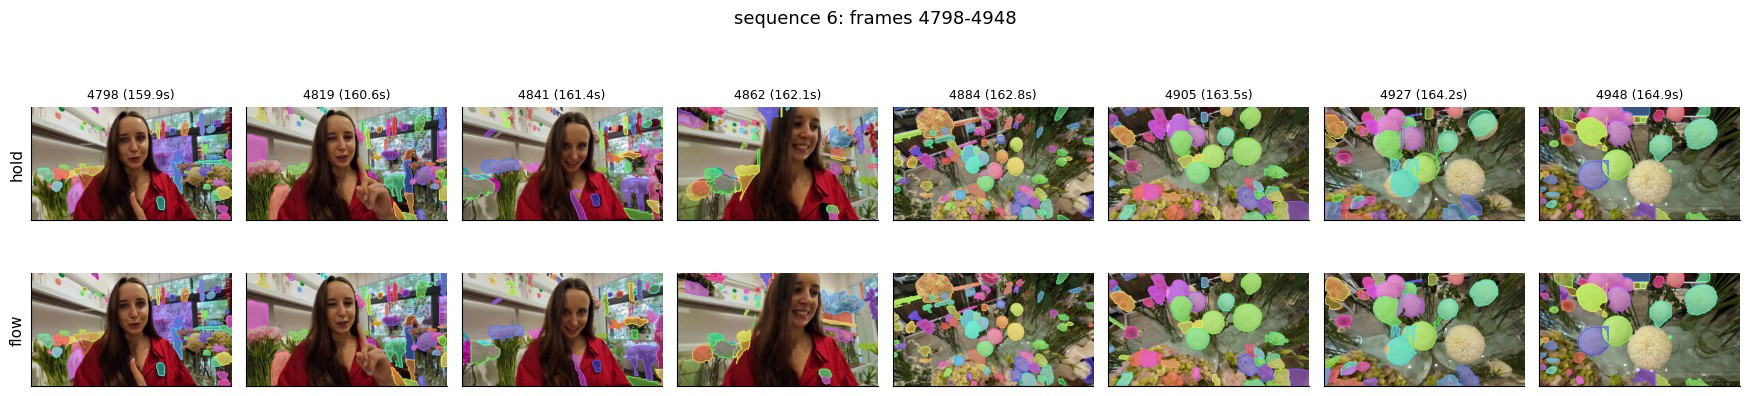

In [9]:
show_filmstrip(6)

## 7 · Did optical flow help?

At every keyframe (after the first), the mask each variant was about to
throw away is compared with the real detection that replaces it (mask IoU:
1.0 is a perfect prediction, 0.0 is no overlap at all). **hold**'s number is
simply "how much the flower moved" between keyframes; **flow** is only useful
if its number is clearly higher.

4047 keyframe transitions, 1190 distinct track ids
iou_hold    0.661
iou_flow    0.783
dtype: float64
flow better in 88% of transitions, hold better in 10%, tied in 3%


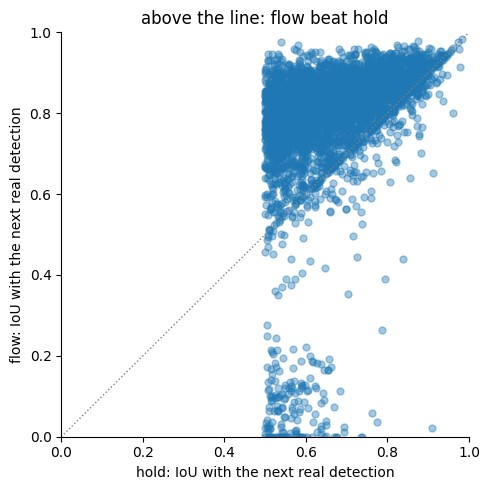

In [10]:
drift = pd.DataFrame(all_drift_rows)
if drift.empty:
    print("no drift rows (only one keyframe per sequence?)")
else:
    print(f"{len(drift)} keyframe transitions, {drift['track'].nunique()} distinct track ids")
    print(drift[["iou_hold", "iou_flow"]].mean().round(3))
    print(f"flow better in {(drift.iou_flow > drift.iou_hold).mean():.0%} of transitions, "
          f"hold better in {(drift.iou_hold > drift.iou_flow).mean():.0%}, "
          f"tied in {(drift.iou_hold == drift.iou_flow).mean():.0%}")
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(drift.iou_hold, drift.iou_flow, alpha=0.4, s=25)
    ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1)
    ax.set_xlabel("hold: IoU with the next real detection")
    ax.set_ylabel("flow: IoU with the next real detection")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title("above the line: flow beat hold")
    plt.tight_layout()
    plt.show()

## 8 · Take-aways

**Cost.** Detecting on 331 keyframes (stride 5, 6 detections/second) took 67 s
in total, about 0.2 s/keyframe - much faster than notebook 05's single-frame
measurement of 0.85-0.96 s/frame for the same setting. The difference is
almost certainly the machine's variable load (noted before as 2-3x) rather
than the stride helping the model itself. Rendering both variants for all
1611 frames (optical flow, warp, colour overlay, video write) took 378 s,
about 0.12 s per frame per variant: cheap, as expected. Total: under 8
minutes for something that would have taken about 27 minutes segmented every
frame, without giving up a smooth-looking, full-frame-rate video.

**Optical flow clearly beats holding still, when a track survives.** Over
4047 keyframe-to-keyframe transitions, the about-to-be-overwritten guess had
mean IoU 0.66 for hold and 0.78 for flow against the real next detection;
flow was better in 88% of transitions, hold in 10%, tied in 3%. So the extra
code (`classical.dense_flow` / `warp_mask`) is worth it whenever there is a
track to propagate.

**But most flower heads never get a track to propagate.** Of the 14096
track ids `link_tracks` created, 88% appear in exactly **one** keyframe and
are gone (a new id starts next keyframe even if it is the same flower); only
about 12% survive to a second keyframe, and the counts fall off fast after
that (393 tracks reach a 3rd keyframe, 191 a 4th, barely a handful reach
double digits). In practice this means the coloured overlay mostly
re-colours the *same* physical flowers every 5 frames rather than tracking
them, which undercuts the point of tracking (and would limit a later idea
like "classify each track every N frames and vote": most tracks would only
ever offer one classification opportunity anyway). This is not a surprise
given notebook 03's finding that SAM 3 keeps only about 40% of its masks
between frames 0.1 s apart - FastSAM-s, a much smaller model, matching only
about 12% of its masks 0.17 s apart is consistent with the same theme
(segmentation masks over video are unstable frame to frame) rather than a
new problem specific to this notebook. Loosening `iou_threshold` below 0.5
would keep more tracks alive but risks linking two different nearby flowers
together; that trade-off was not explored here.

**Optical flow is not risk-free.** The scatter in section 7 has a visible
cluster of a few hundred transitions where flow's IoU collapses towards 0
despite the track having been linked in the first place (hold's IoU for the
same points stays moderate, 0.5-0.9): a bad flow estimate can throw the mask
completely off the object, usually where motion is fast or the flower has
little texture for Farneback to lock onto. Flow wins on average, not on
every frame.

**A real failure mode neither method can fix: hard cuts.** Sequence 6's
filmstrip (section 6) jumps from a close-up of the person talking to an
overhead shot of a shelf of flowers between frames 4862 and 4884, a scene
cut inside what was assumed to be one continuous 5-second window, not a pan
or a camera move. Both hold and flow keep drawing the old shot's colours for
a moment because neither has any way to know the shot changed - there is no
motion to estimate across a cut. Building the "windows around picks" logic
should probably detect and split on cuts (e.g. a sudden collapse in optical
flow confidence, or a big frame-difference spike) rather than assuming any
5-second span is one continuous shot.

**The grey filter change looks reasonable but was not directly measured.**
`min_sat=0` was used throughout this notebook (no min_sat=40 baseline run
here for comparison), and white/pale flowers - the pompom-like white blooms
in sequence 6's later frames, for example - are visibly outlined, which they
would not have been under notebook 05's default. Whether this brings in much
new *background* clutter (pale wrapping paper, pale walls) was not checked
quantitatively; section 12 of notebook 05 would need to be re-run with
`min_sat=0` to say so with numbers.

**Next step, if this is worth pursuing further:** the actual bottleneck is
not the propagation method but the linking itself. Worth trying before more
tracking machinery: a lower `iou_threshold`, matching on colour/position in
addition to IoU, or (closer to the parked plan) training a small detector
whose masks are consistent enough between frames for `match_instances` to
work as intended.